# Khám phá dữ liệu (EDA) – Dự đoán thời gian giao hàng

Mục tiêu: hiểu dữ liệu Olist trước khi xây mô hình.

1. Tổng quan 6 bảng gốc: kích thước, giá trị thiếu, khoá nối
2. Trạng thái đơn hàng & phạm vi thời gian
3. Biến mục tiêu `delivery_days`
4. Xu hướng theo thời gian
5. Địa lý: bang, tuyến, khoảng cách
6. Sản phẩm, giá, phí vận chuyển
7. Ước tính của Olist & giao trễ
8. Tương quan các đặc trưng với target
9. Tóm tắt phát hiện

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data_prep import load_raw, build_dataset
from src.utils import load_config, resolve

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 100
cfg = load_config()
RAW = resolve(cfg["paths"]["raw_dir"])

## 1. Tổng quan các bảng gốc

In [2]:
raw = load_raw(RAW)
pd.DataFrame({n: {"rows": len(d), "cols": d.shape[1],
                  "missing_cells": int(d.isna().sum().sum()),
                  "duplicate_rows": int(d.duplicated().sum())}
              for n, d in raw.items()}).T

,rows,cols,missing_cells,duplicate_rows
orders,99441,8,4908,0
order_items,112650,7,0,0
customers,99441,5,0,0
sellers,3095,4,0,0
products,32951,9,2448,0
geolocation,1000163,5,0,261831


In [3]:
for n, d in raw.items():
    miss = d.isna().sum()
    miss = miss[miss > 0]
    if len(miss):
        print(f"--- {n}")
        print((miss / len(d) * 100).round(2).astype(str).add(" %").to_string())

--- orders
order_approved_at                0.16 %
order_delivered_carrier_date     1.79 %
order_delivered_customer_date    2.98 %
--- products
product_category_name         1.85 %
product_name_lenght           1.85 %
product_description_lenght    1.85 %
product_photos_qty            1.85 %
product_weight_g              0.01 %
product_length_cm             0.01 %
product_height_cm             0.01 %
product_width_cm              0.01 %


Kiểm tra khoá nối giữa các bảng:

In [4]:
o, it, c, s, p, g = (raw[k] for k in ["orders", "order_items", "customers", "sellers", "products", "geolocation"])
geo_zips = set(g["geolocation_zip_code_prefix"])
checks = {
    "orders.order_id duy nhất": o["order_id"].is_unique,
    "orders.customer_id có trong customers": o["customer_id"].isin(c["customer_id"]).mean(),
    "orders có item": o["order_id"].isin(it["order_id"]).mean(),
    "items.product_id có trong products": it["product_id"].isin(p["product_id"]).mean(),
    "items.seller_id có trong sellers": it["seller_id"].isin(s["seller_id"]).mean(),
    "customer zip có toạ độ": c["customer_zip_code_prefix"].isin(geo_zips).mean(),
    "seller zip có toạ độ": s["seller_zip_code_prefix"].isin(geo_zips).mean(),
}
pd.Series(checks, name="tỉ lệ / kết quả")

orders.order_id duy nhất                     True
orders.customer_id có trong customers         1.0
orders có item                           0.992206
items.product_id có trong products            1.0
items.seller_id có trong sellers              1.0
customer zip có toạ độ                   0.997204
seller zip có toạ độ                     0.997738
Name: tỉ lệ / kết quả, dtype: object

## 2. Trạng thái đơn hàng & phạm vi thời gian

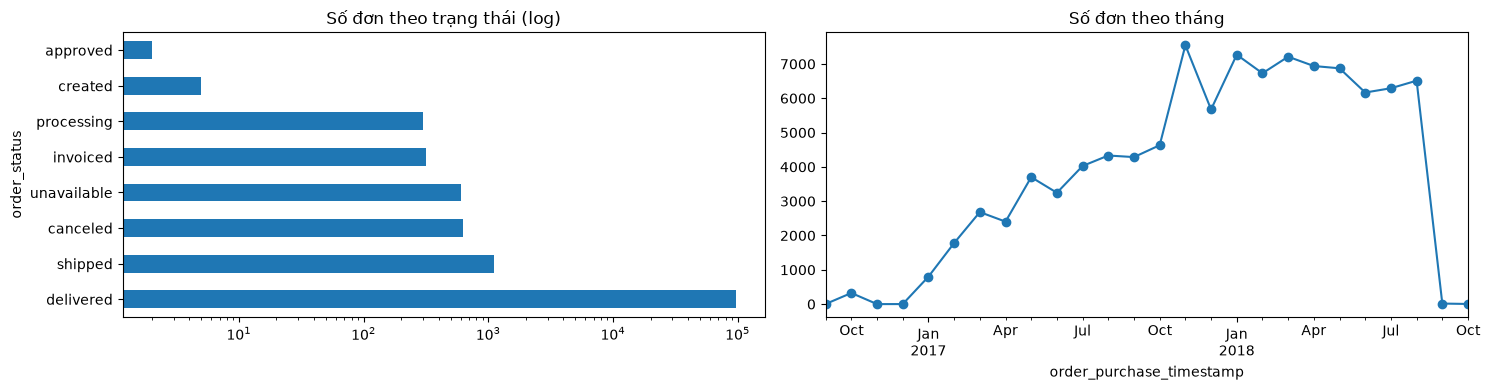

Thời gian: 2016-09-04 21:15:19 -> 2018-10-17 17:30:18
order_status
delivered      97.02
shipped         1.11
canceled        0.63
unavailable     0.61
invoiced        0.32
Name: proportion, dtype: float64


In [5]:
for col in ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
            "order_delivered_customer_date", "order_estimated_delivery_date"]:
    o[col] = pd.to_datetime(o[col])

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
o["order_status"].value_counts().plot.barh(ax=ax[0], logx=True, title="Số đơn theo trạng thái (log)")
o.set_index("order_purchase_timestamp").resample("ME")["order_id"].count().plot(ax=ax[1], marker="o",
    title="Số đơn theo tháng")
plt.tight_layout(); plt.show()
print("Thời gian:", o.order_purchase_timestamp.min(), "->", o.order_purchase_timestamp.max())
print(o["order_status"].value_counts(normalize=True).mul(100).round(2).head())

Đơn `delivered` nhưng thiếu ngày giao, hoặc có thứ tự mốc thời gian bất thường:

In [6]:
d = o[o.order_status == "delivered"]
pd.Series({
    "delivered nhưng thiếu ngày giao khách": d.order_delivered_customer_date.isna().sum(),
    "delivered nhưng thiếu ngày duyệt": d.order_approved_at.isna().sum(),
    "giao cho hãng vận chuyển TRƯỚC khi đặt": (d.order_delivered_carrier_date < d.order_purchase_timestamp).sum(),
    "khách nhận TRƯỚC khi giao cho hãng": (d.order_delivered_customer_date < d.order_delivered_carrier_date).sum(),
})

delivered nhưng thiếu ngày giao khách       8
delivered nhưng thiếu ngày duyệt           14
giao cho hãng vận chuyển TRƯỚC khi đặt    165
khách nhận TRƯỚC khi giao cho hãng         23
dtype: int64

Kiểm tra **dữ liệu bị cắt cuối kỳ**: nếu các tháng cuối có nhiều đơn chưa giao (`shipped`, `invoiced`…), target của các tháng này sẽ bị lệch thấp vì thiếu những đơn giao lâu.

In [7]:
st = pd.crosstab(o.order_purchase_timestamp.dt.to_period("M"), o.order_status, normalize="index")
undelivered = 1 - st["delivered"] - st.get("canceled", 0) - st.get("unavailable", 0)
undelivered.loc["2017-06":"2018-08"].mul(100).round(2).rename("% chưa giao").to_frame().T

order_purchase_timestamp,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08
% chưa giao,2.16,1.84,1.82,1.8,1.49,1.78,1.89,1.62,1.04,2.29,1.74,1.22,0.75,1.18,1.07


## 3. Biến mục tiêu `delivery_days`

Dùng bộ dữ liệu sau tiền xử lý (1 dòng / đơn) từ `src.data_prep.build_dataset` — chưa cắt ngoại lai để thấy toàn bộ phân phối.

In [8]:
df = build_dataset(raw, outlier_quantile=1.0)
df["order_purchase_timestamp"] = pd.to_datetime(df["order_purchase_timestamp"])
y = df["delivery_days"]
print(df.shape)
y.describe(percentiles=[.05, .25, .5, .75, .95, .99, .995]).round(2)

(96470, 32)


count    96470.00
mean        12.56
std          9.55
min          0.53
5%           3.02
25%          6.77
50%         10.22
75%         15.72
95%         29.27
99%         46.05
99.5%       54.06
max        209.63
Name: delivery_days, dtype: float64

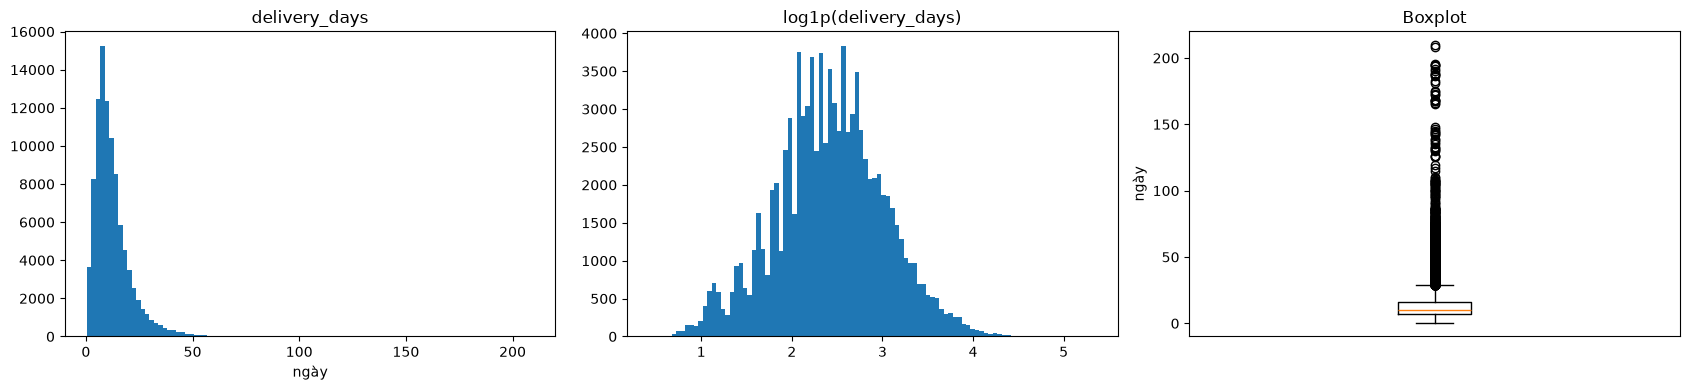

Skewness: 3.83  |  log1p skew: 0.04
> 60 ngày: 306 đơn, ngưỡng 99.5%: 54.1 ngày


In [9]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].hist(y, bins=100); ax[0].set(title="delivery_days", xlabel="ngày")
ax[1].hist(np.log1p(y), bins=100); ax[1].set(title="log1p(delivery_days)")
ax[2].boxplot(y); ax[2].set(title="Boxplot", ylabel="ngày", xticks=[])
plt.tight_layout(); plt.show()
print(f"Skewness: {y.skew():.2f}  |  log1p skew: {np.log1p(y).skew():.2f}")
print(f"> 60 ngày: {(y > 60).sum()} đơn, ngưỡng 99.5%: {y.quantile(.995):.1f} ngày")

Thời gian giao tách theo từng chặng: duyệt đơn → giao cho hãng → đến khách.

In [10]:
d = d.dropna(subset=["order_approved_at", "order_delivered_carrier_date", "order_delivered_customer_date"])
stages = pd.DataFrame({
    "1_duyệt": (d.order_approved_at - d.order_purchase_timestamp).dt.total_seconds() / 86400,
    "2_người bán xử lý": (d.order_delivered_carrier_date - d.order_approved_at).dt.total_seconds() / 86400,
    "3_vận chuyển": (d.order_delivered_customer_date - d.order_delivered_carrier_date).dt.total_seconds() / 86400,
})
neg = (stages < 0).sum()
print("Số đơn có thời lượng âm (mốc thời gian lỗi):", neg.to_dict())
stages[(stages >= 0).all(axis=1)].describe().round(2)

Số đơn có thời lượng âm (mốc thời gian lỗi): {'1_duyệt': 0, '2_người bán xử lý': 1350, '3_vận chuyển': 23}


,1_duyệt,2_người bán xử lý,3_vận chuyển
count,95082.00,95082.00,95082.00
mean,0.40,2.85,9.36
std,0.80,3.48,8.77
min,0.00,0.00,0.00
25%,0.01,0.90,4.11
50%,0.01,1.85,7.11
75%,0.56,3.62,12.06
max,30.89,125.76,205.19


## 4. Xu hướng theo thời gian

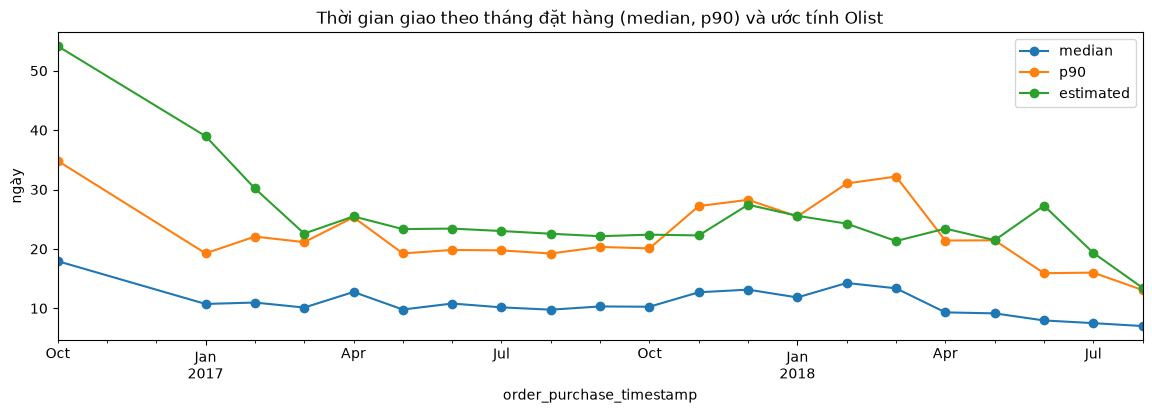

order_purchase_timestamp,2016-10,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08
n,265.00,750.00,1653.00,2546.00,2303.00,3545.00,3135.00,3872.00,4193.00,4150.00,4478.00,7288.00,5513.00,7069.00,6555.00,7003.00,6798.00,6749.00,6096.00,6156.00,6351.00
median,17.94,10.73,10.97,10.13,12.75,9.79,10.80,10.16,9.77,10.31,10.26,12.70,13.14,11.83,14.26,13.37,9.31,9.15,7.96,7.50,7.01
p90,34.83,19.26,22.07,21.14,25.32,19.24,19.82,19.75,19.22,20.33,20.09,27.21,28.26,25.46,31.02,32.19,21.42,21.45,15.91,16.01,13.07
estimated,54.15,38.98,30.18,22.59,25.47,23.34,23.42,23.01,22.55,22.14,22.40,22.27,27.44,25.57,24.26,21.32,23.42,21.46,27.28,19.33,13.44


In [11]:
m = df.groupby(df.order_purchase_timestamp.dt.to_period("M")).agg(
    n=("order_id", "size"), median=("delivery_days", "median"),
    p90=("delivery_days", lambda x: x.quantile(.9)), estimated=("estimated_days", "median"))
m = m[m.n >= 100]
ax = m[["median", "p90", "estimated"]].plot(figsize=(14, 4), marker="o")
ax.set(ylabel="ngày", title="Thời gian giao theo tháng đặt hàng (median, p90) và ước tính Olist")
plt.show()
m.round(2).T

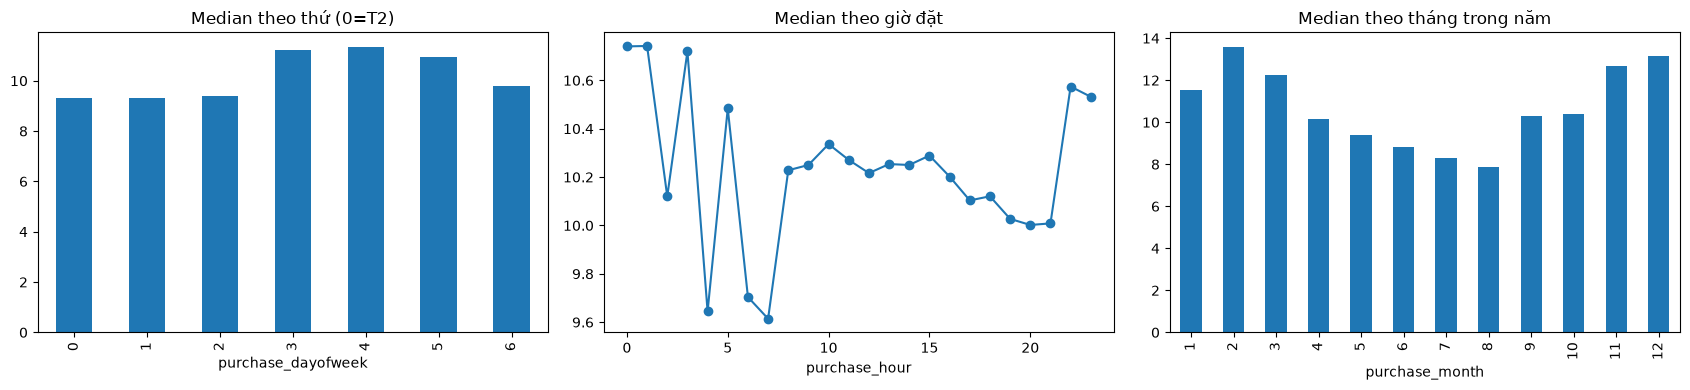

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
df.groupby("purchase_dayofweek")["delivery_days"].median().plot.bar(ax=ax[0], title="Median theo thứ (0=T2)")
df.groupby("purchase_hour")["delivery_days"].median().plot(ax=ax[1], marker="o", title="Median theo giờ đặt")
df.groupby("purchase_month")["delivery_days"].median().plot.bar(ax=ax[2], title="Median theo tháng trong năm")
plt.tight_layout(); plt.show()

## 5. Địa lý

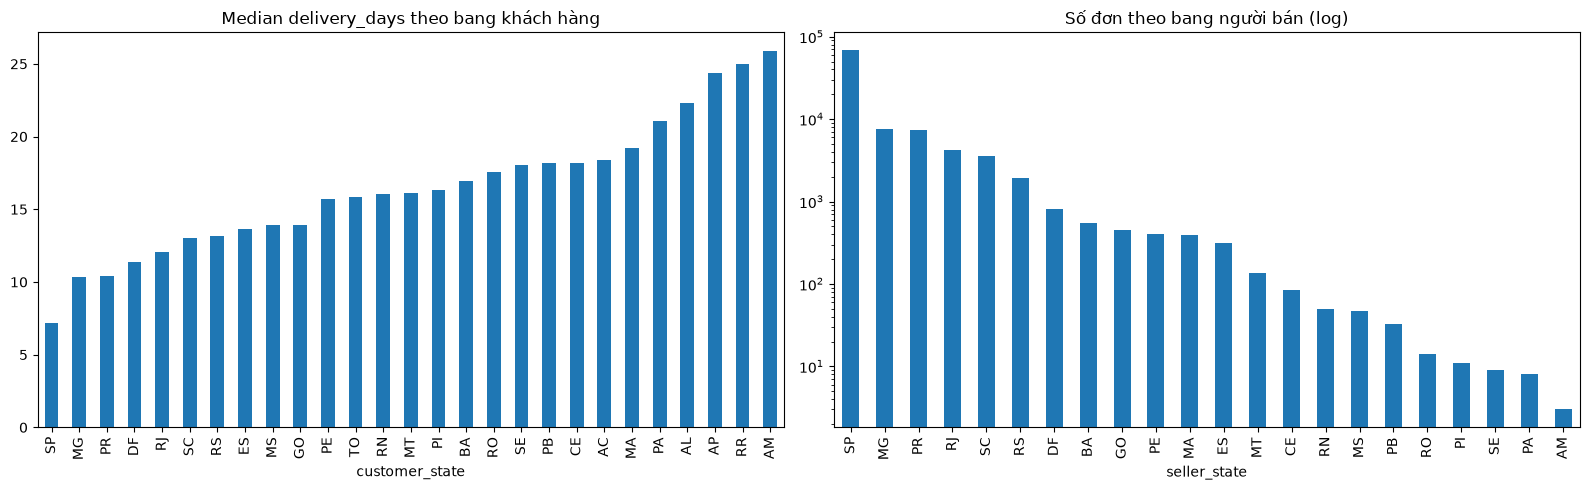

customer_state,SP,MG,PR,DF,RJ,SC,RS,ES,MS,GO,PE,TO,RN,MT,PI,BA,RO,SE,PB,CE,AC,MA,PA,AL,AP,RR,AM
count,40494.00,11354.00,4923.00,2080.00,12350.00,3546.00,5344.00,1995.00,701.00,1957.00,1593.00,274.00,474.00,886.00,476.00,3256.00,243.00,335.00,517.00,1279.00,80.00,717.00,946.00,397.00,67.00,41.00,145.00
median,7.21,10.31,10.43,11.36,12.04,13.01,13.18,13.64,13.94,13.95,15.70,15.87,16.06,16.11,16.29,16.91,17.58,18.01,18.15,18.21,18.36,19.19,21.08,22.33,24.35,25.01,25.88
mean,8.76,12.01,11.99,12.97,15.31,14.95,15.30,15.79,15.62,15.61,18.45,17.66,19.28,18.06,19.46,19.34,19.37,21.52,20.43,21.27,21.04,21.57,23.77,24.54,27.19,29.39,26.43


In [13]:
st = df.groupby("customer_state")["delivery_days"].agg(["count", "median", "mean"]).sort_values("median")
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
st["median"].plot.bar(ax=ax[0], title="Median delivery_days theo bang khách hàng")
df["seller_state"].value_counts().plot.bar(ax=ax[1], logy=True, title="Số đơn theo bang người bán (log)")
plt.tight_layout(); plt.show()
st.round(2).T

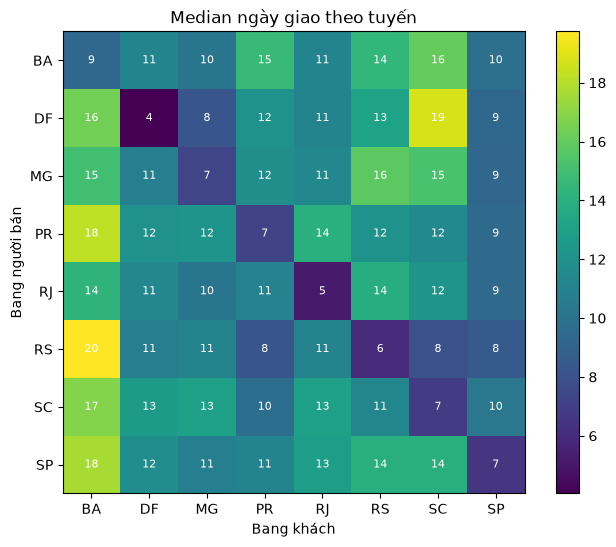

In [14]:
top = df["customer_state"].value_counts().index[:8]
route = (df[df.customer_state.isin(top) & df.seller_state.isin(top)]
         .pivot_table(index="seller_state", columns="customer_state", values="delivery_days", aggfunc="median"))
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(route, cmap="viridis")
ax.set(xticks=range(len(route.columns)), xticklabels=route.columns, yticks=range(len(route.index)),
       yticklabels=route.index, xlabel="Bang khách", ylabel="Bang người bán", title="Median ngày giao theo tuyến")
for i in range(route.shape[0]):
    for j in range(route.shape[1]):
        ax.text(j, i, f"{route.iat[i, j]:.0f}", ha="center", va="center", color="w", fontsize=8)
plt.colorbar(im); plt.show()

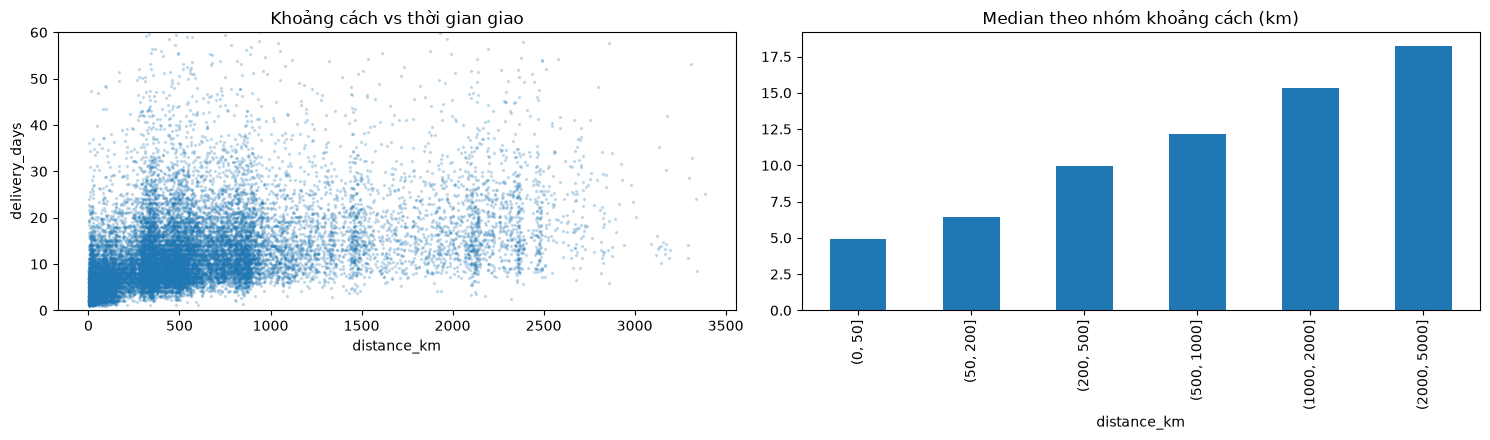

Spearman(distance, days) = 0.542
same_state: {0: 12.79, 1: 6.54}


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
smp = df.sample(min(20000, len(df)), random_state=0)
ax[0].scatter(smp.distance_km, smp.delivery_days, s=2, alpha=.2)
ax[0].set(xlabel="distance_km", ylabel="delivery_days", ylim=(0, 60), title="Khoảng cách vs thời gian giao")
bins = pd.cut(df.distance_km, [0, 50, 200, 500, 1000, 2000, 5000])
df.groupby(bins, observed=True)["delivery_days"].median().plot.bar(ax=ax[1], title="Median theo nhóm khoảng cách (km)")
plt.tight_layout(); plt.show()
print("Spearman(distance, days) =", round(df[["distance_km", "delivery_days"]].corr("spearman").iat[0, 1], 3))
print("same_state:", df.groupby("same_state")["delivery_days"].median().round(2).to_dict())

## 6. Sản phẩm, giá, phí vận chuyển

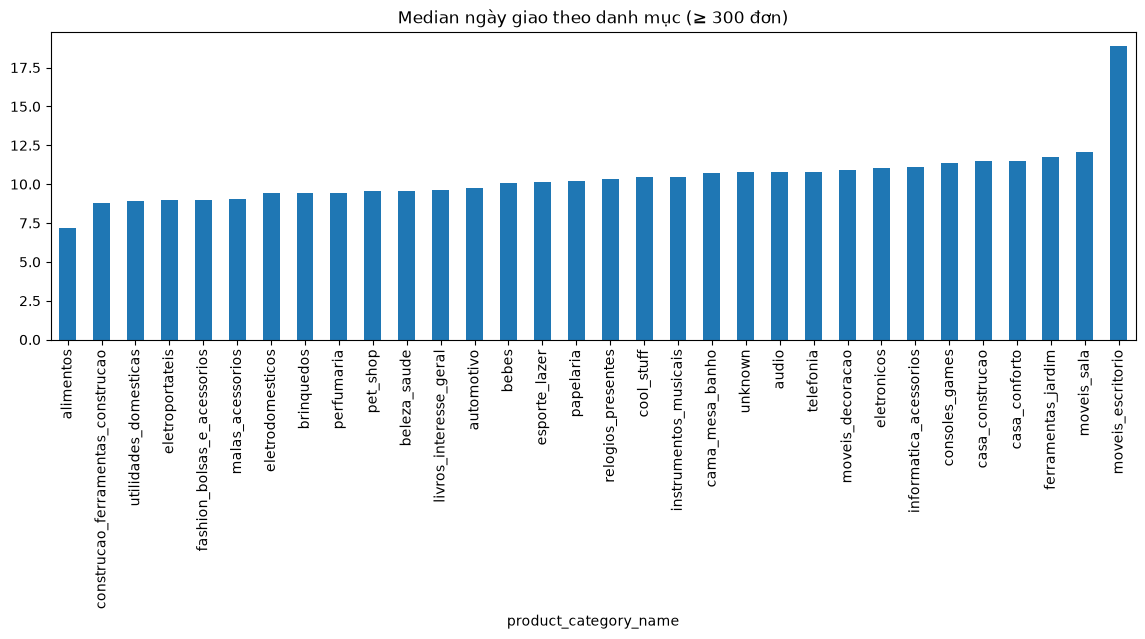

74 danh mục; top 10 chiếm 63% số đơn


In [16]:
cat = df.groupby("product_category_name")["delivery_days"].agg(["count", "median"])
cat = cat[cat["count"] >= 300].sort_values("median")
fig, ax = plt.subplots(figsize=(14, 4))
cat["median"].plot.bar(ax=ax, title="Median ngày giao theo danh mục (≥ 300 đơn)")
plt.show()
print(f"{df.product_category_name.nunique()} danh mục; top 10 chiếm "
      f"{df.product_category_name.value_counts(normalize=True).head(10).sum():.0%} số đơn")

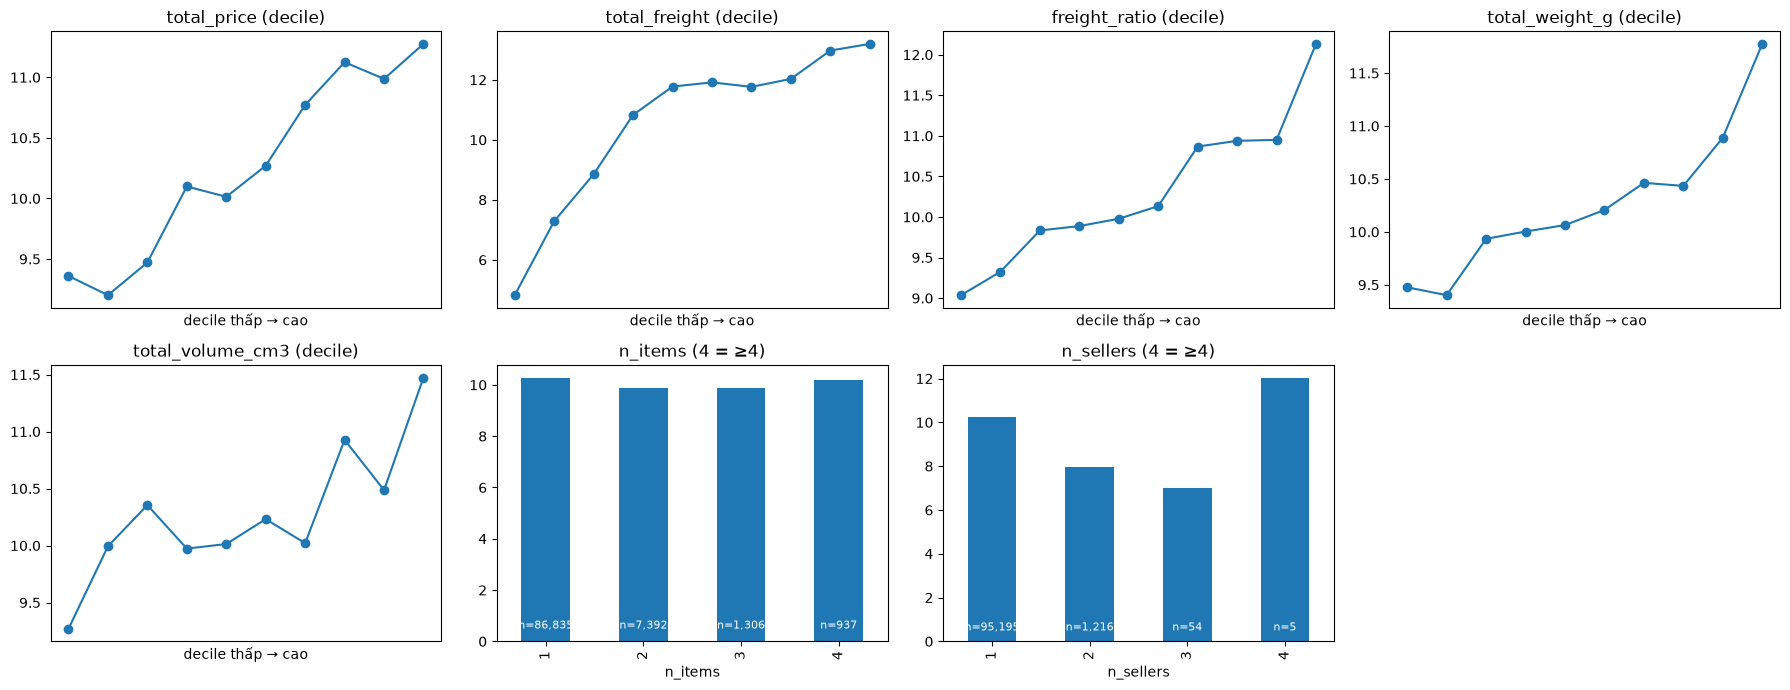

,total_price,total_freight,freight_ratio,total_weight_g,total_volume_cm3,n_items,n_sellers
count,96470.00,96470.00,96470.00,96470.00,96470.00,96470.00,96470.00
mean,137.04,22.79,0.31,2386.60,17330.26,1.14,1.01
std,209.05,21.56,0.31,4769.76,30141.67,0.54,0.12
min,0.85,0.00,0.00,0.00,168.00,1.00,1.00
25%,45.90,13.85,0.13,300.00,2964.00,1.00,1.00
50%,86.50,17.17,0.22,750.00,7250.00,1.00,1.00
75%,149.90,24.02,0.38,2050.00,19866.00,1.00,1.00
max,13440.00,1794.96,21.45,184400.00,1476000.00,21.00,5.00


In [17]:
cont = ["total_price", "total_freight", "freight_ratio", "total_weight_g", "total_volume_cm3"]
disc = ["n_items", "n_sellers"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
# Biến liên tục: chia 10 nhóm theo decile của chính giá trị
for ax, c in zip(axes.flat, cont):
    q = pd.qcut(df[c], 10, duplicates="drop")
    df.groupby(q, observed=True)["delivery_days"].median().plot(ax=ax, marker="o", title=f"{c} (decile)")
    ax.set_xticks([]); ax.set_xlabel("decile thấp → cao")
# Biến rời rạc (~90% bằng 1): nhóm theo giá trị, gộp đuôi
for ax, c in zip(axes.flat[len(cont):], disc):
    v = df[c].clip(upper=4)
    g = df.groupby(v)["delivery_days"].agg(["median", "count"])
    g["median"].plot.bar(ax=ax, title=f"{c} (4 = ≥4)")
    for i, n in enumerate(g["count"]):
        ax.text(i, 0.5, f"n={n:,}", ha="center", color="w", fontsize=8)
axes.flat[-1].axis("off")
plt.tight_layout(); plt.show()
df[cont + disc].describe().round(2)

## 7. Ước tính của Olist & giao trễ

Tỉ lệ giao trễ so với ước tính: 8.1%
Ước tính / thực tế (median): 2.21 lần


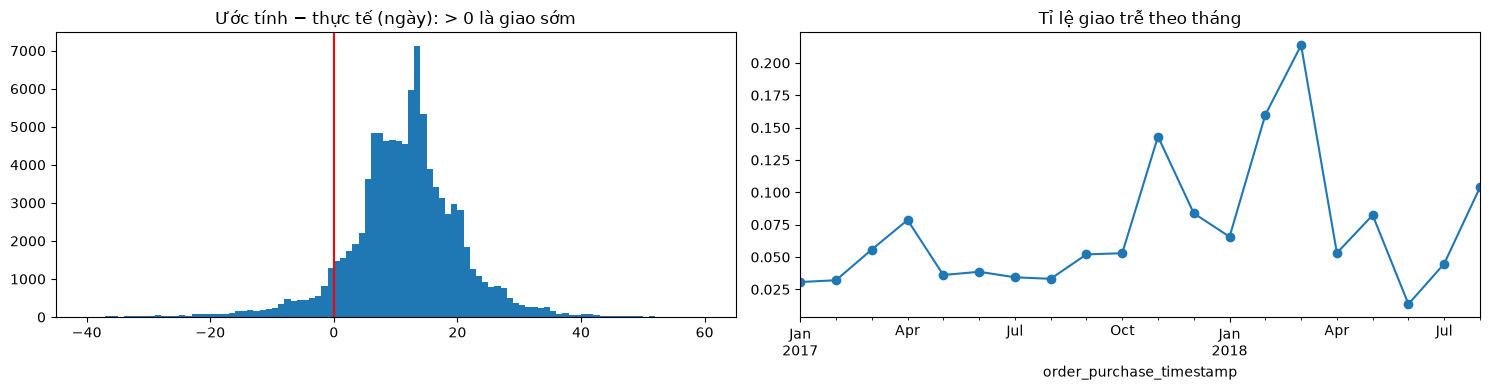

In [18]:
late = df.delivery_days > df.estimated_days
print(f"Tỉ lệ giao trễ so với ước tính: {late.mean():.1%}")
print(f"Ước tính / thực tế (median): {(df.estimated_days / df.delivery_days).median():.2f} lần")
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ax[0].hist(df.estimated_days - df.delivery_days, bins=100, range=(-40, 60))
ax[0].axvline(0, c="r"); ax[0].set(title="Ước tính − thực tế (ngày): > 0 là giao sớm")
late.groupby(df.order_purchase_timestamp.dt.to_period("M")).mean().loc["2017-01":].plot(
    ax=ax[1], marker="o", title="Tỉ lệ giao trễ theo tháng")
plt.tight_layout(); plt.show()

## 8. Tương quan với target

In [19]:
num = df.select_dtypes("number").drop(columns=["delivery_days"])
corr = pd.DataFrame({"pearson": num.corrwith(df.delivery_days),
                     "spearman": num.corrwith(df.delivery_days, method="spearman")})
corr.reindex(corr.spearman.abs().sort_values(ascending=False).index).round(3)

,pearson,spearman
distance_km,0.393,0.542
estimated_days,0.384,0.522
same_state,-0.362,-0.495
total_freight,0.167,0.382
customer_lat,0.258,0.264
same_city,-0.165,-0.242
freight_ratio,0.080,0.121
max_price,0.059,0.107
total_price,0.056,0.102
seller_lat,0.052,0.101


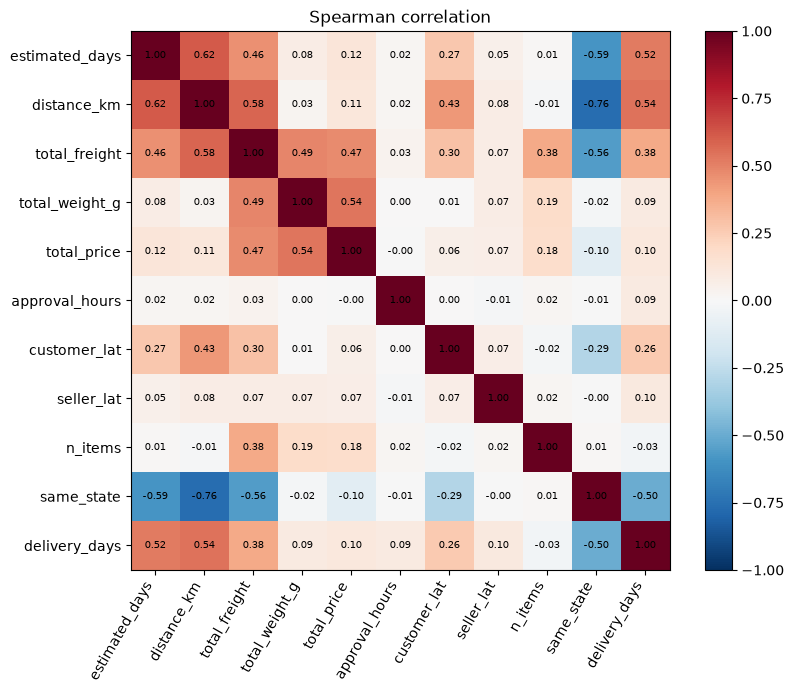

In [20]:
feat = ["estimated_days", "distance_km", "total_freight", "total_weight_g", "total_price", "approval_hours",
        "customer_lat", "seller_lat", "n_items", "same_state"]
cm = df[feat + ["delivery_days"]].corr("spearman")
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set(xticks=range(len(cm)), xticklabels=cm.columns, yticks=range(len(cm)), yticklabels=cm.columns)
plt.setp(ax.get_xticklabels(), rotation=60, ha="right")
for i in range(len(cm)):
    for j in range(len(cm)):
        ax.text(j, i, f"{cm.iat[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im); ax.set_title("Spearman correlation"); plt.show()

## 9. Tóm tắt phát hiện

**Chất lượng dữ liệu**
- 99,441 đơn (09/2016 – 10/2018); 97% là `delivered` → chỉ dùng đơn đã giao (~96.5k sau khi ghép).
- Thiếu dữ liệu ít: ngày giao khách 3% (chủ yếu đơn chưa giao), thông tin sản phẩm 1.85%.
- `geolocation` có 262k dòng trùng và nhiều toạ độ/zip → cần gộp median theo zip; 99.7% zip khách/người bán có toạ độ.
- Có mốc thời gian bất thường: 165 đơn giao cho hãng *trước* khi đặt, ~1,350 đơn giao cho hãng *trước* khi duyệt → `order_delivered_carrier_date` không đáng tin và còn gây leakage → không dùng.
- Không bị cắt cuối kỳ: tỉ lệ đơn chưa giao ở 06–08/2018 (~1%) không cao hơn các tháng trước → target của test không bị lệch thấp giả tạo; thời gian giao giảm là thật.

**Biến mục tiêu**
- Median 10.2 ngày, trung bình 12.6, lệch phải mạnh (skew 3.8, max 210 ngày). `log1p` gần như đối xứng (skew 0.04) → cân nhắc train trên log hoặc dùng loss MAE.
- Phần lớn thời gian nằm ở chặng **vận chuyển** (median 7.1 ngày) so với người bán xử lý (1.8 ngày).

**Thời gian**
- Thời gian giao **thay đổi mạnh theo thời gian**: tăng vọt cuối 2017 – đầu 2018 (median 13–14 ngày, mùa Black Friday/Tết), rồi giảm nhanh còn ~7 ngày giữa 2018. Đây là lý do baseline học từ dữ liệu cũ đoán dư trên test.
- Thứ trong tuần, giờ đặt hàng gần như không ảnh hưởng.

**Địa lý – nhóm đặc trưng mạnh nhất**
- Bang khách: SP ~7 ngày, các bang phía Bắc (AM, RR, AP) ~25 ngày.
- Cùng bang: 6.5 ngày vs khác bang: 12.8 ngày.
- `distance_km` có Spearman 0.54 – mạnh nhất; người bán tập trung ở SP.

**Sản phẩm & giá**
- 74 danh mục, top 10 chiếm 63% đơn; khác biệt giữa danh mục vừa phải.
- `total_freight` tương quan khá (0.38) – phí ship phản ánh khoảng cách & kích thước. Giá, cân nặng, thể tích tăng nhẹ theo thời gian giao; số món và số người bán gần như không ảnh hưởng.

**Ước tính của Olist**
- Chỉ 8.1% đơn giao trễ; ước tính dài gấp ~2.2 lần thực tế nhưng tương quan tốt (0.52) và **tự điều chỉnh theo thời gian** → đặc trưng rất hữu ích.

**Hệ quả cho mô hình**
1. Ưu tiên đặc trưng địa lý + `estimated_days` + `total_freight`.
2. Xử lý trôi theo thời gian (feature xu hướng, trọng số đơn gần, train lại với val).
3. Target lệch → loss MAE hoặc biến đổi log.
